Detected BASE_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results
Detected OUTPUT_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\xcTranslator-eNet-comparison_results
Model_Z: 1809 files found
Model_Rank: 600 files found
Model_Bin: 2141 files found
Model_None: 2128 files found
Common proteins across all 4 models: 488
(488, 5)


,Dataset,Model_Z_MSE,Model_Rank_MSE,Model_Bin_MSE,Model_None_MSE
0,A2M,0.836941,1.651979,1.217487,0.917467
1,AARS2,0.140420,0.384579,0.250606,0.149635
2,AASDHPPT,0.273664,0.594917,0.302285,0.227209
3,ABCB7,0.147214,0.400277,0.251066,0.153209
4,ABCD3,0.202043,0.687798,0.292869,0.196429


C:\Users\hp\AppData\Local\Temp\ipykernel_41072\2098386468.py:143: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary_df, x="Model", y="Mean_MSE", palette=palette)


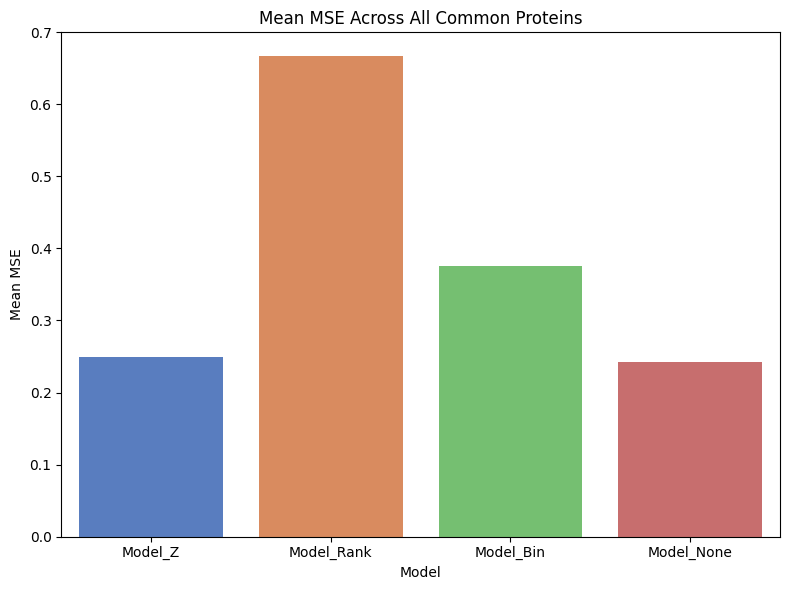


=== Winning Model Analysis (MSE) ===


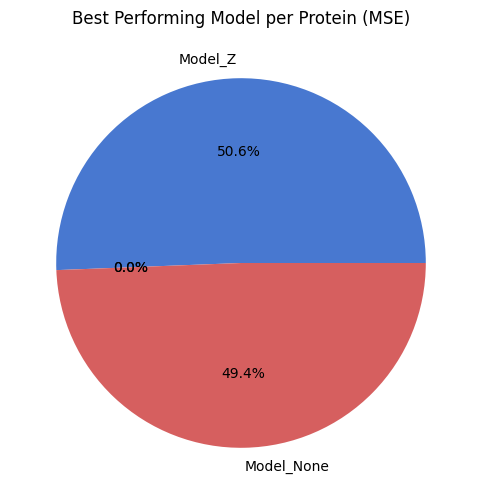

Saved results to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\xcTranslator-eNet-comparison_results


In [5]:
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cwd = os.getcwd()
base_candidates = [
    os.path.join(cwd, "model_results"),
    os.path.join(os.path.dirname(cwd), "model_results"),
]

BASE_DIR = next((p for p in base_candidates if os.path.isdir(p)), None)

if BASE_DIR is None:
    raise FileNotFoundError(
        "Could not find 'model_results'. Checked:\n" + "\n".join(base_candidates)
    )

parent_dir = os.path.dirname(BASE_DIR)

if os.path.basename(cwd) == "xcTranslator-eNet-comparison_results":
    OUTPUT_DIR = cwd
elif os.path.isdir(os.path.join(parent_dir, "xcTranslator-eNet-comparison_results")):
    OUTPUT_DIR = os.path.join(parent_dir, "xcTranslator-eNet-comparison_results")
else:
    OUTPUT_DIR = os.path.join(parent_dir, "xcTranslator-eNet-comparison_results")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIRS = {
    "Model_Z": "results_z",
    "Model_Rank": "results_rk",
    "Model_Bin": "results_bin",
    "Model_None": "results_none",
}

models = ["Model_Z", "Model_Rank", "Model_Bin", "Model_None"]
palette = sns.color_palette("muted", len(models))

MSE_ALIASES = ["MSE", "mse", "mse_all_others"]

def protein_from_filename(path):
    name = os.path.basename(path)
    if name.endswith("_best.csv"):
        return name[:-9]
    return os.path.splitext(name)[0]

def find_col(df, aliases):
    col_map = {c.lower(): c for c in df.columns}
    for a in aliases:
        if a.lower() in col_map:
            return col_map[a.lower()]
    return None

def safe_scalar(x):
    try:
        if pd.isna(x):
            return np.nan
        return float(x)
    except Exception:
        return np.nan

def load_mse(csv_path):
    df = pd.read_csv(csv_path)
    if df.empty:
        return np.nan
    row = df.iloc[0]
    col = find_col(df, MSE_ALIASES)
    if col is None:
        return np.nan
    return safe_scalar(row[col])

files_by_model = {}

print("Detected BASE_DIR:", BASE_DIR)
print("Detected OUTPUT_DIR:", OUTPUT_DIR)

for model_name, folder_name in MODEL_DIRS.items():
    folder_path = os.path.join(BASE_DIR, folder_name)

    if not os.path.isdir(folder_path):
        print(f"{model_name}: folder not found -> {folder_path}")
        files_by_model[model_name] = {}
        continue

    csv_files = [
        os.path.join(folder_path, f)
        for f in os.listdir(folder_path)
        if f.endswith("_best.csv")
    ]

    files_by_model[model_name] = {
        protein_from_filename(f): f for f in csv_files
    }

    print(f"{model_name}: {len(csv_files)} files found")

if any(len(v) == 0 for v in files_by_model.values()):
    print("\nOne or more model folders have no matching *_best.csv files.")
    for model_name in models:
        folder_path = os.path.join(BASE_DIR, MODEL_DIRS[model_name])
        if os.path.isdir(folder_path):
            print(f"{model_name} sample files in {folder_path}: {os.listdir(folder_path)[:10]}")

common_sets = [set(d.keys()) for d in files_by_model.values() if len(d) > 0]
common_proteins = sorted(set.intersection(*common_sets)) if len(common_sets) == 4 else []

print(f"Common proteins across all 4 models: {len(common_proteins)}")

records = []

for protein in common_proteins:
    rec = {"Dataset": protein}
    for model_name in models:
        csv_path = files_by_model[model_name][protein]
        rec[f"{model_name}_MSE"] = load_mse(csv_path)
    records.append(rec)

comp_df = pd.DataFrame(records)

print(comp_df.shape)
if not comp_df.empty:
    display(comp_df.head())

mse_cols = [f"{m}_MSE" for m in models]
available_mse_cols = [c for c in mse_cols if c in comp_df.columns]

summary_rows = []
for m in models:
    col = f"{m}_MSE"
    if col in comp_df.columns:
        summary_rows.append({
            "Model": m,
            "Mean_MSE": comp_df[col].mean(skipna=True)
        })

summary_df = pd.DataFrame(summary_rows)

if not summary_df.empty:
    plt.figure(figsize=(8, 6))
    sns.barplot(data=summary_df, x="Model", y="Mean_MSE", palette=palette)
    plt.title("Mean MSE Across All Common Proteins")
    plt.ylabel("Mean MSE")
    plt.xlabel("Model")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "model_mean_mse_bar.png"), dpi=300, bbox_inches="tight")
    plt.show()

print("\n=== Winning Model Analysis (MSE) ===")

if not comp_df.empty:
    scalar_df = comp_df[["Dataset"] + mse_cols].dropna()

    if not scalar_df.empty:
        stack = scalar_df[mse_cols].to_numpy().T
        winners_idx = np.argmin(stack, axis=0)
        counts = Counter(winners_idx)
        sizes = [counts.get(i, 0) for i in range(len(models))]
        total = sum(sizes)

        if total > 0:
            labels = [
                models[i] if (sizes[i] / total) * 100 >= 5 else ""
                for i in range(len(models))
            ]

            plt.figure(figsize=(6, 6))
            plt.pie(
                sizes,
                labels=labels,
                autopct="%1.1f%%",
                colors=palette
            )
            plt.title("Best Performing Model per Protein (MSE)")
            plt.savefig(os.path.join(OUTPUT_DIR, "mse_winner_pie_overall.png"), dpi=300, bbox_inches="tight")
            plt.show()

comp_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_table.csv"), index=False)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "model_mean_mse_summary.csv"), index=False)

print(f"Saved results to: {OUTPUT_DIR}")